In [1]:
import os
import torch
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import medmnist
from medmnist import DermaMNIST

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300

DATA_DIR = os.path.abspath("../data")
FIG_DIR = os.path.abspath("../reports/figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Redimensionamento metodológico para padronização de patches 4x4
transform_derma = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

train_dataset = DermaMNIST(split="train", download=True, root=DATA_DIR, transform=transform_derma)
val_dataset = DermaMNIST(split="val", download=True, root=DATA_DIR, transform=transform_derma)
test_dataset = DermaMNIST(split="test", download=True, root=DATA_DIR, transform=transform_derma)

derma_classes = {
    0: 'Actinic keratoses (akiec)',
    1: 'Basal cell carcinoma (bcc)',
    2: 'Benign keratosis (bkl)',
    3: 'Dermatofibroma (df)',
    4: 'Melanocytic nevi (nv)',
    5: 'Melanoma (mel)',
    6: 'Vascular lesions (vasc)'
}

print(f"=== DermaMNIST (HAM10000): Divisões de Dados ===")
print(f"Treino: {len(train_dataset)} | Validação: {len(val_dataset)} | Teste: {len(test_dataset)}")
print(f"Dimensão Ajustada para o Pipeline: {train_dataset[0][0].shape}")

=== DermaMNIST (HAM10000): Divisões de Dados ===
Treino: 7007 | Validação: 1003 | Teste: 2005
Dimensão Ajustada para o Pipeline: torch.Size([3, 32, 32])


Análise do Balanceamento de Classes

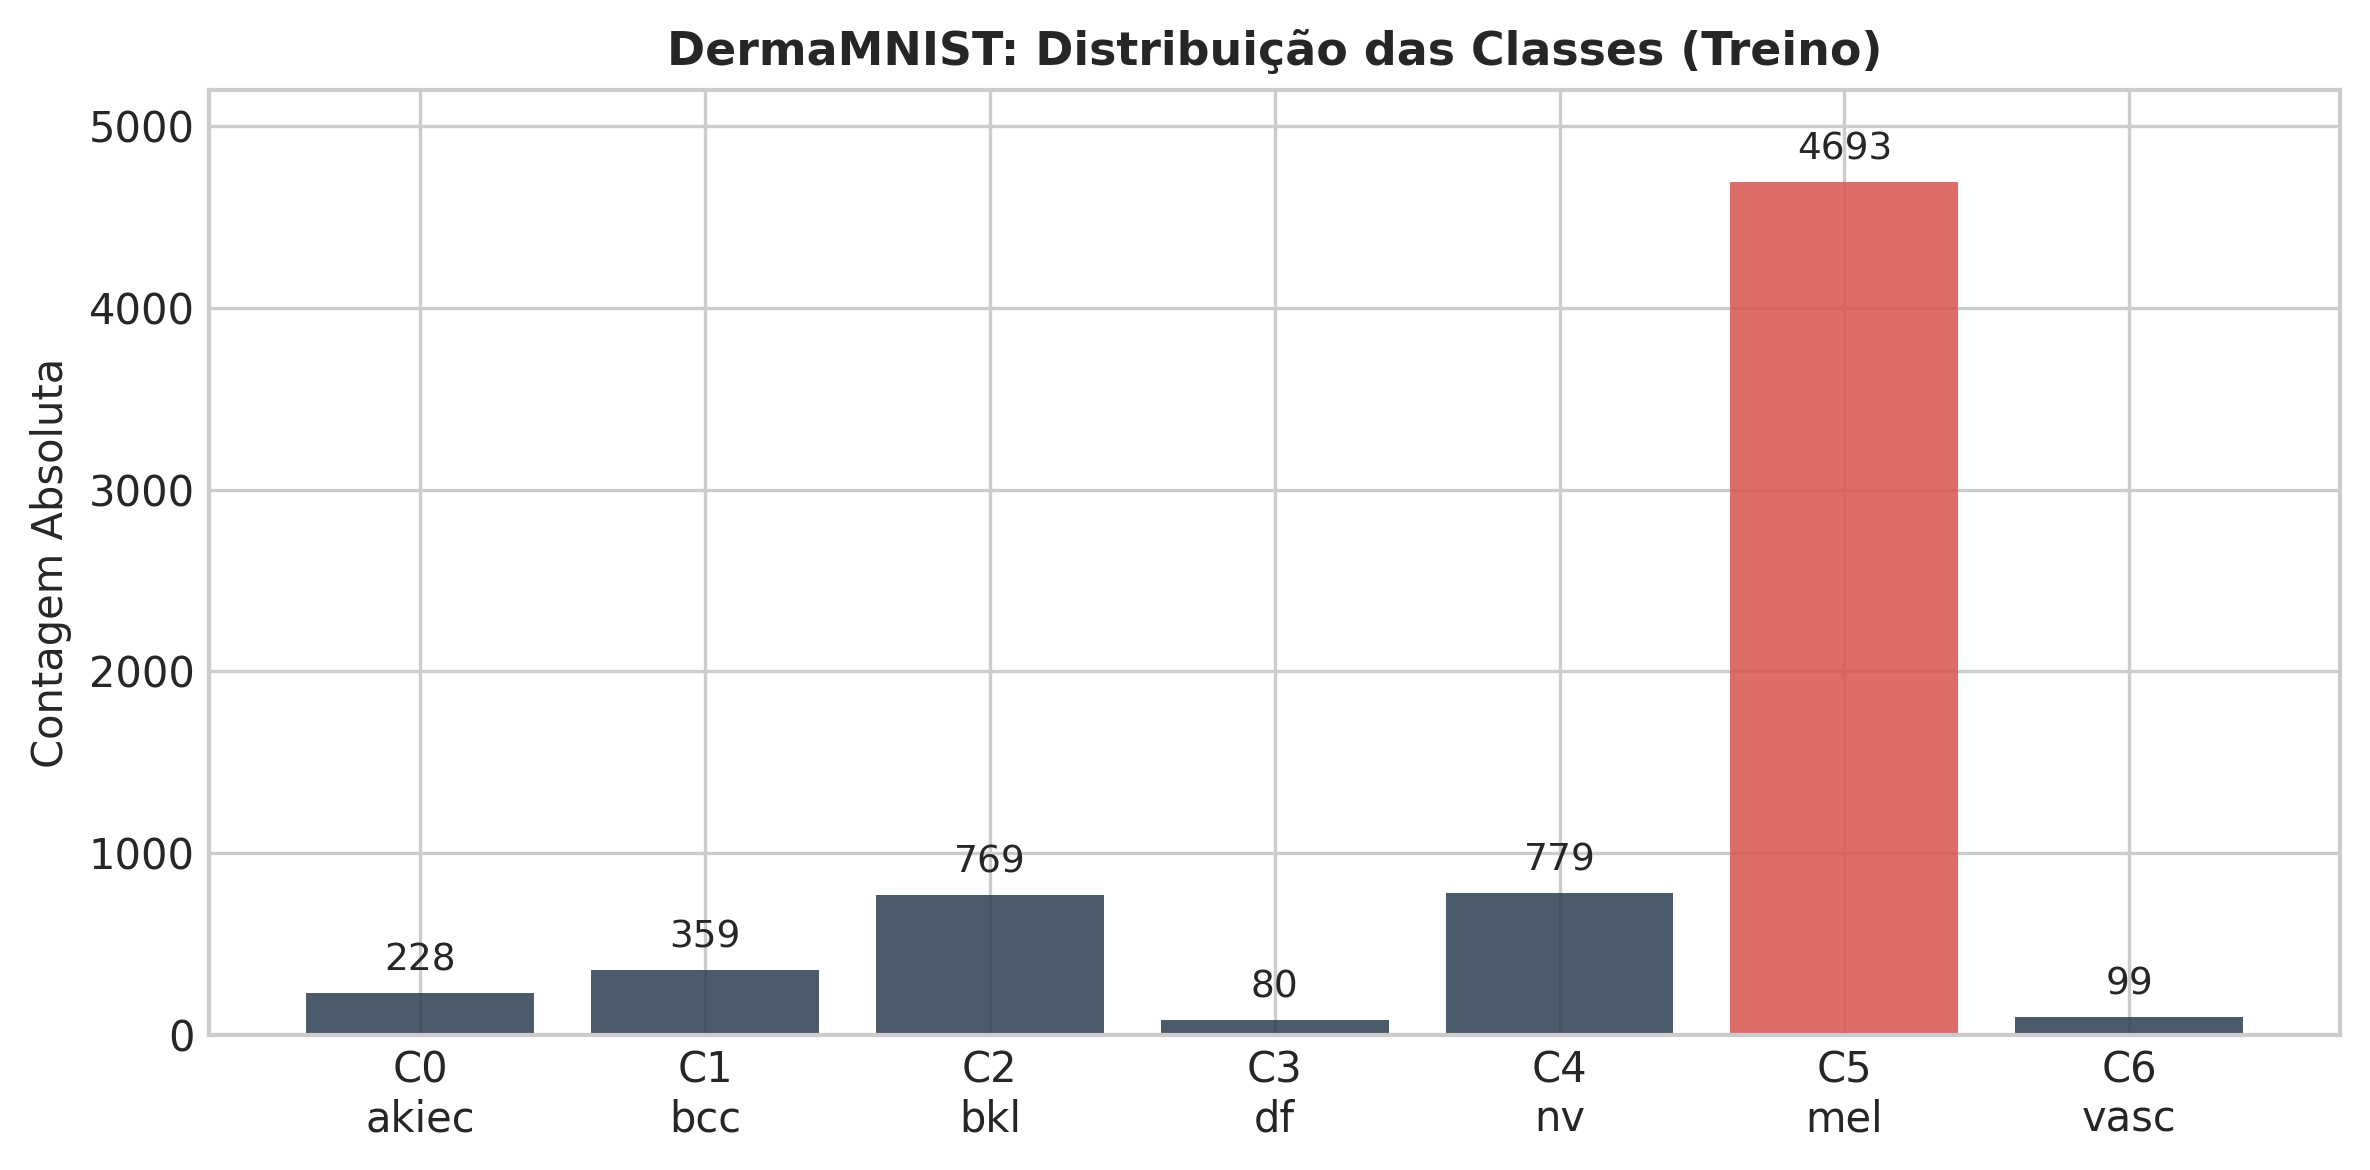

=== Métrica de Assimetria ===
Classe Dominante (C4 - nv): 779 amostras
Classe Rara (C3 - df): 80 amostras
Imbalance Ratio (IR): 58.66 (Extremamente desbalanceado!)


In [2]:
labels = [int(x) for x in train_dataset.labels.squeeze()]
counts = Counter(labels)
sorted_counts = [counts[i] for i in range(7)]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#d9534f' if i == 5 else '#2c3e50' for i in range(7)] # Destaca Melanoma em vermelho

bars = ax.bar([f"C{i}\n{derma_classes[i].split('(')[1][:-1]}" for i in range(7)], sorted_counts, color=colors, alpha=0.85)
ax.set_title("DermaMNIST: Distribuição das Classes (Treino)", fontsize=11, fontweight='bold')
ax.set_ylabel("Contagem Absoluta")

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 80, f'{height}', ha='center', va='bottom', fontsize=9)

ax.set_ylim(0, 5200)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_dermamnist_imbalance.png"), dpi=300, bbox_inches='tight')
plt.show()

ir = max(sorted_counts) / min(sorted_counts)
print(f"=== Métrica de Assimetria ===")
print(f"Classe Dominante (C4 - nv): {counts[4]} amostras")
print(f"Classe Rara (C3 - df): {counts[3]} amostras")
print(f"Imbalance Ratio (IR): {ir:.2f} (Extremamente desbalanceado!)")

Painel Clínico Visual (7 Classes de Lesões Dermatológicas)

/tmp/ipykernel_16465/3563371580.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  l = int(lbl)


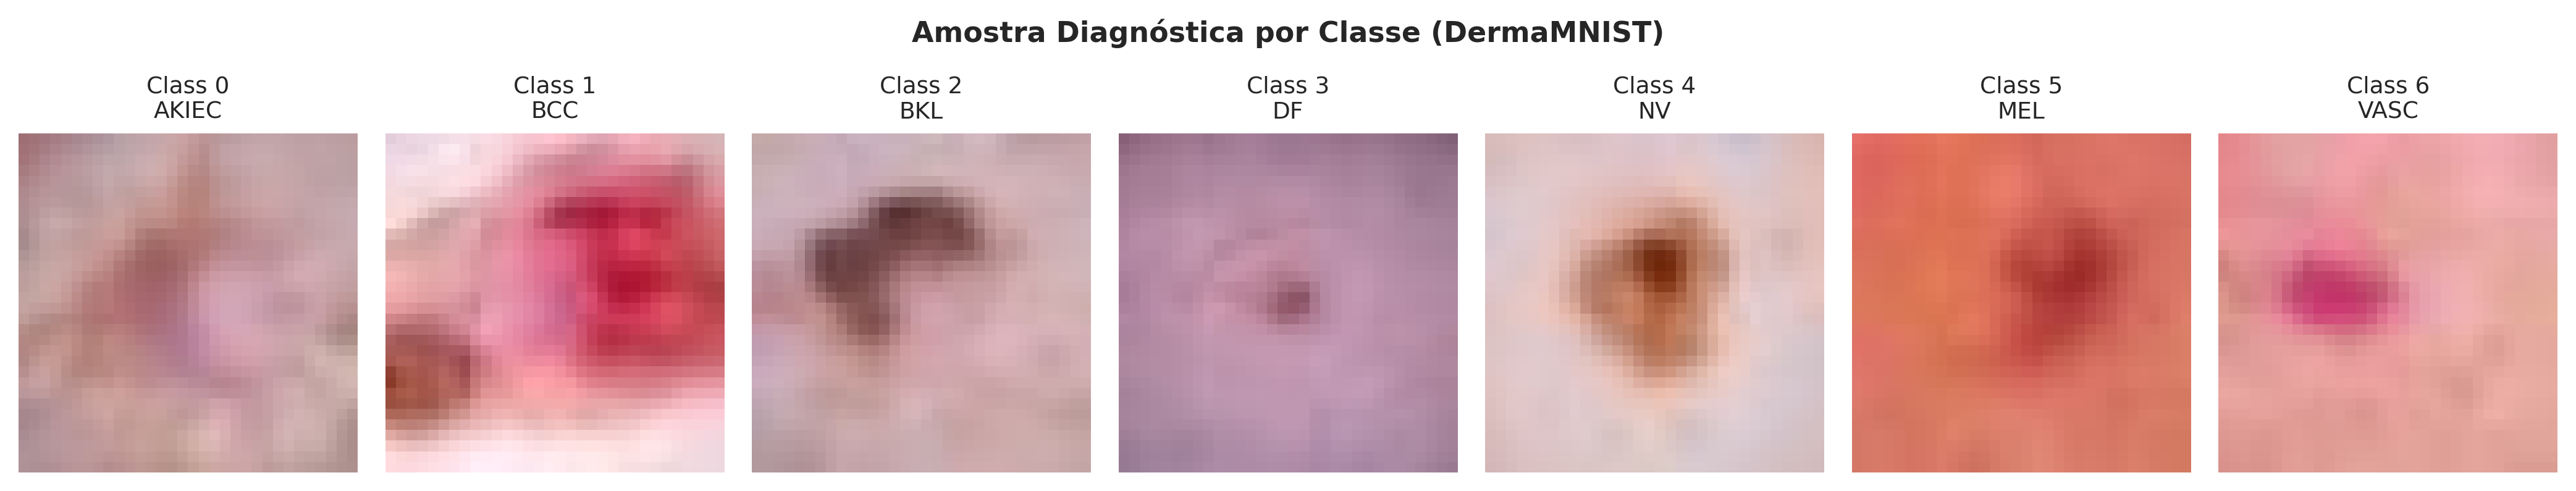

In [3]:
fig, axes = plt.subplots(1, 7, figsize=(14, 2.5))
fig.suptitle("Amostra Diagnóstica por Classe (DermaMNIST)", fontsize=11, fontweight='bold', y=1.05)

found = {}
for img, lbl in train_dataset:
    l = int(lbl)
    if l not in found:
        found[l] = img
    if len(found) == 7:
        break

for i in range(7):
    img_np = found[i].permute(1, 2, 0).numpy()
    axes[i].imshow(img_np)
    axes[i].set_title(f"Class {i}\n{derma_classes[i].split('(')[1][:-1].upper()}", fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_dermamnist_samples.png"), dpi=300, bbox_inches='tight')
plt.show()

Visualização da Grade de Patches $4 \times 4$ e Extração de Média/Std

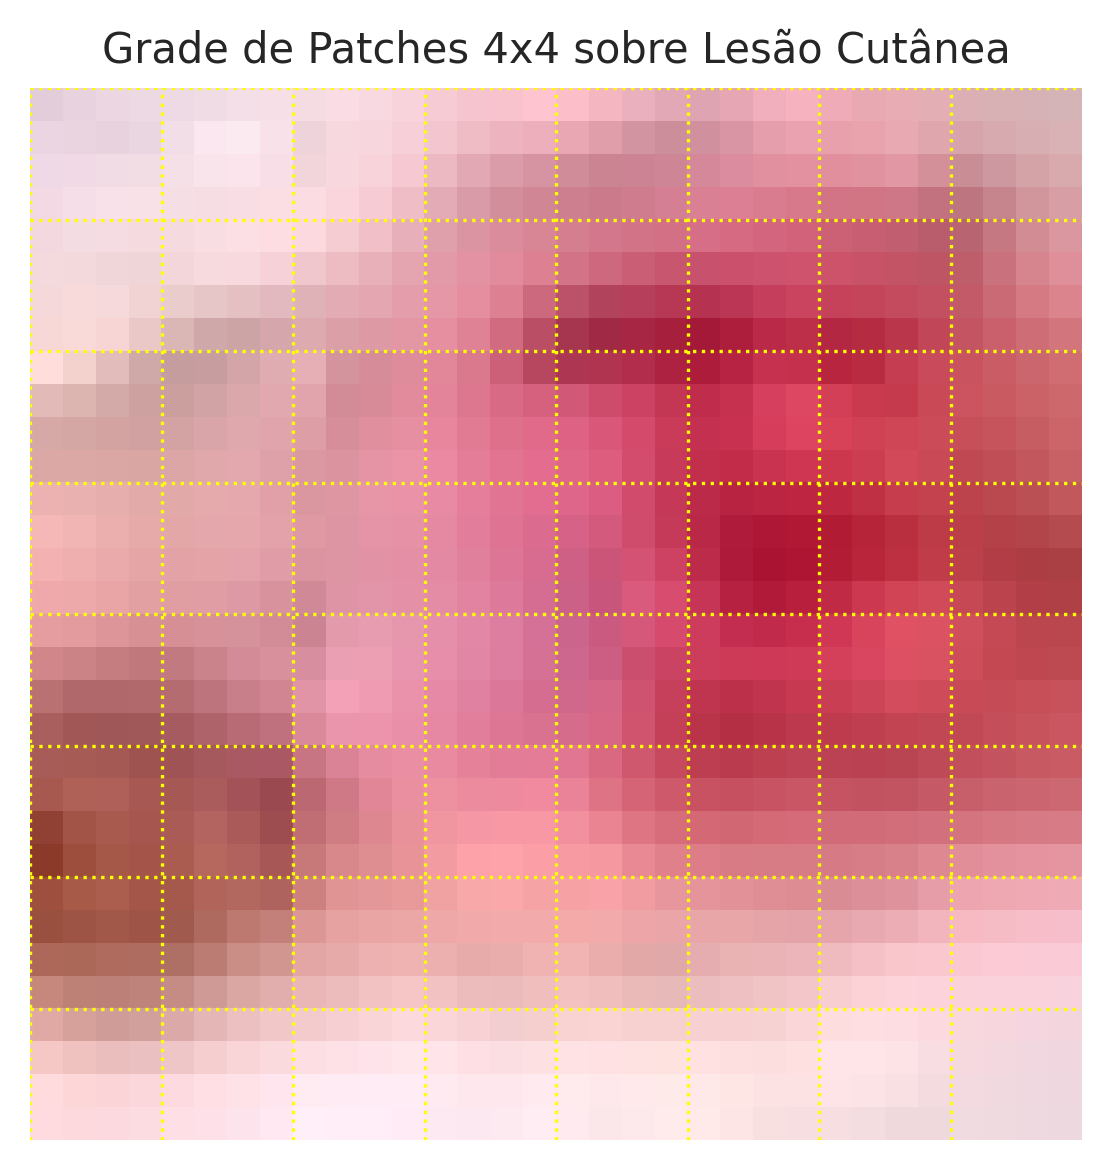

=== Parâmetros para PyTorch Normalization (DermaMNIST) ===
mean = [0.7632, 0.5382, 0.5615]
std  = [0.0863, 0.1127, 0.1240]


In [4]:
# Overlay do Fatiamento de Patches
sample_img, _ = train_dataset[12]
img_np = sample_img.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img_np)

for x in range(0, 32, 4):
    ax.axvline(x - 0.5, color='yellow', linestyle=':', linewidth=0.8)
    ax.axhline(x - 0.5, color='yellow', linestyle=':', linewidth=0.8)

ax.set_title("Grade de Patches 4x4 sobre Lesão Cutânea", fontsize=10)
ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_patch_grid_derma.png"), dpi=300, bbox_inches='tight')
plt.show()

# Normalização Específica
loader = torch.utils.data.DataLoader(train_dataset, batch_size=500, shuffle=False)
mean, std, total = torch.zeros(3), torch.zeros(3), 0

for images, _ in loader:
    b = images.size(0)
    images = images.view(b, images.size(1), -1)
    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total += b

mean /= total
std /= total

print("=== Parâmetros para PyTorch Normalization (DermaMNIST) ===")
print(f"mean = [{mean[0]:.4f}, {mean[1]:.4f}, {mean[2]:.4f}]")
print(f"std  = [{std[0]:.4f}, {std[1]:.4f}, {std[2]:.4f}]")